In [2]:

import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"

df = pd.read_excel(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Dataset loaded successfully!
Dataset shape: (541909, 8)

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [3]:

# Check missing values and duplicate records
print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Convert date column to datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

# Remove rows with missing descriptions or invalid numeric values
df = df.dropna(subset=["Description", "InvoiceDate", "Quantity", "UnitPrice"]).copy()

# Keep positive quantities and prices
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()

# Calculate revenue
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print("\nDataset shape after cleaning:", df.shape)
print("Total revenue: £{:,.2f}".format(df["Revenue"].sum()))
print("\nCleaned data preview:")
display(df.head())


Missing values before cleaning:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268

Dataset shape after cleaning: (524878, 9)
Total revenue: £10,642,110.80

Cleaned data preview:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


Top 10 countries by revenue:


,Country,Revenue
0,United Kingdom,9001744.094
1,Netherlands,285446.340
2,EIRE,283140.520
3,Germany,228678.400
4,France,209625.370
5,Australia,138453.810
6,Spain,61558.560
7,Switzerland,57067.600
8,Belgium,41196.340
9,Sweden,38367.830


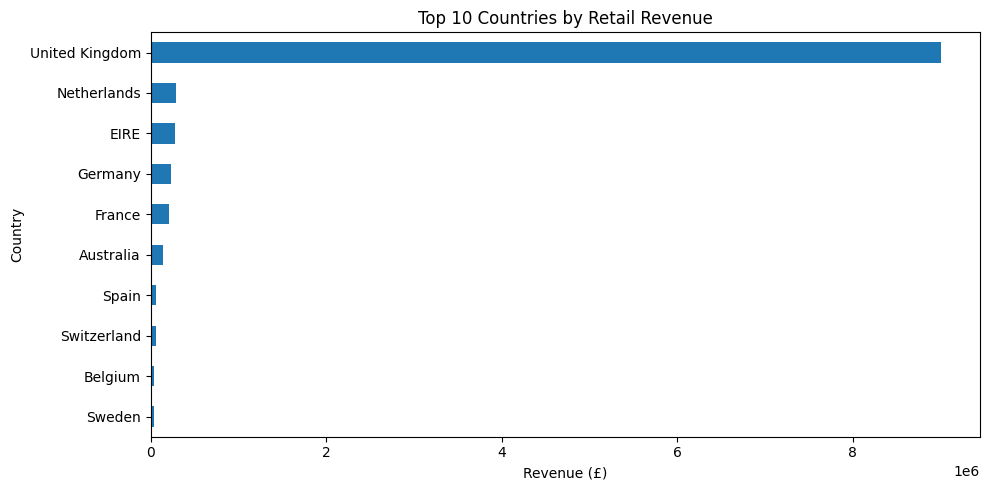

In [5]:

import matplotlib.pyplot as plt

# 1. Revenue by country (top 10)
country_revenue = (
    df.groupby("Country")["Revenue"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print("Top 10 countries by revenue:")
display(country_revenue.reset_index())

plt.figure(figsize=(10, 5))
country_revenue.sort_values().plot(kind="barh")
plt.title("Top 10 Countries by Retail Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()




Top 10 products by revenue:


,Description,Revenue
0,DOTCOM POSTAGE,206248.77
1,REGENCY CAKESTAND 3 TIER,174156.54
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,WHITE HANGING HEART T-LIGHT HOLDER,106236.72
4,PARTY BUNTING,99445.23
5,JUMBO BAG RED RETROSPOT,94159.81
6,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
7,POSTAGE,78101.88
8,Manual,77752.82
9,RABBIT NIGHT LIGHT,66870.03


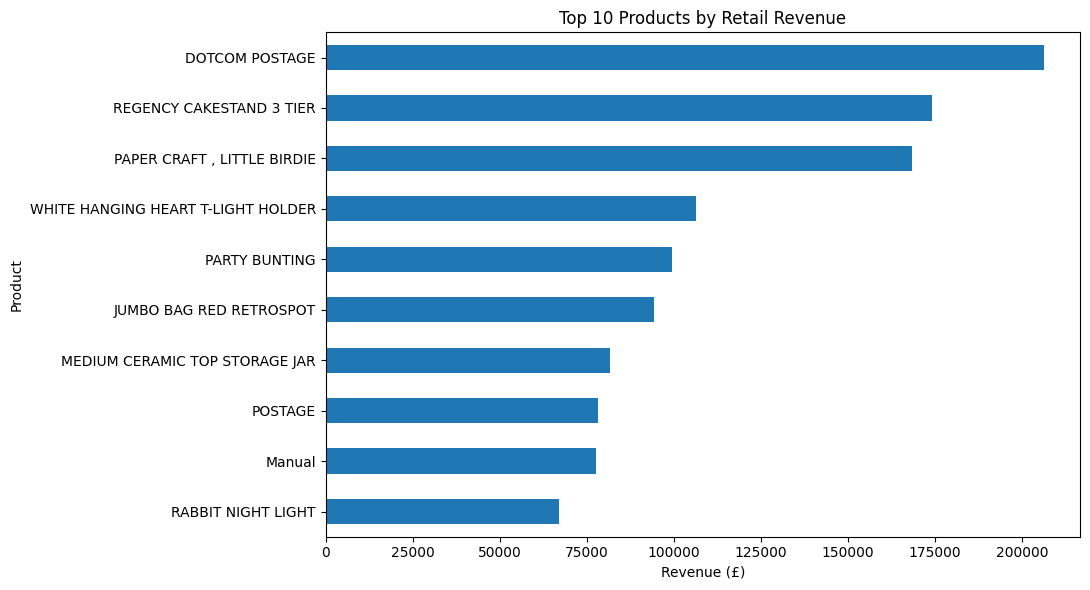

In [6]:
# 2. Revenue by product (top 10 descriptions)
product_revenue = (
    df.groupby("Description")["Revenue"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print("Top 10 products by revenue:")
display(product_revenue.reset_index())

plt.figure(figsize=(11, 6))
product_revenue.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Retail Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


Monthly revenue:


,YearMonth,Revenue
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,757841.380
9,2011-09,1056435.192


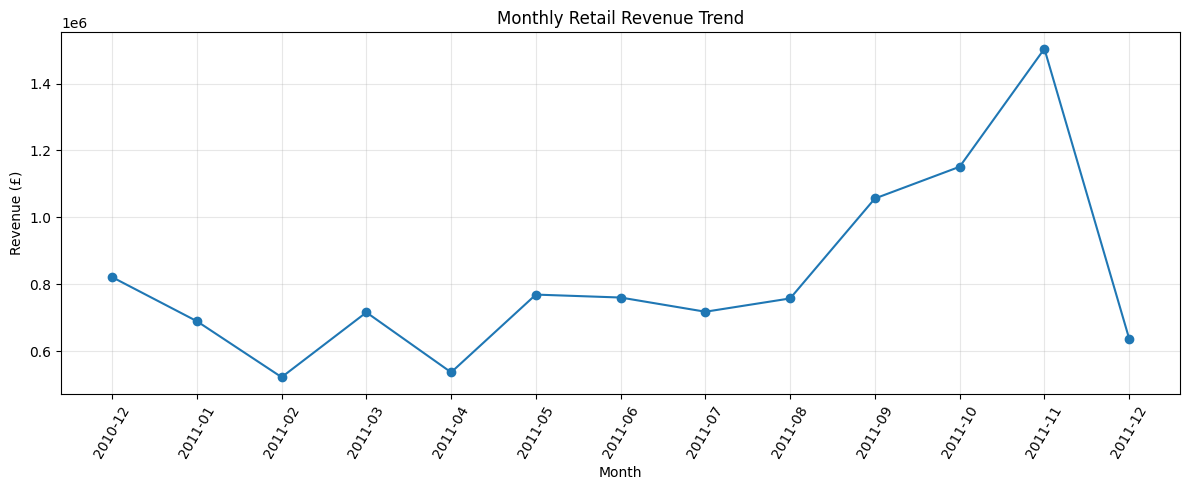

In [7]:

# Extract year and month
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")

# Calculate monthly revenue
monthly_revenue = (
    df.groupby("YearMonth")["Revenue"]
      .sum()
      .sort_index()
)

print("Monthly revenue:")
display(monthly_revenue.reset_index())

# Plot monthly revenue
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Retail Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Customer segment counts:


,Segment,CustomerCount
0,Other Active,1649
1,Dormant,1449
2,High Value,747
3,At Risk,493



Top 10 customers by total spending:


,CustomerID,TotalSpent,TotalOrders,LastPurchase,DaysSinceLastPurchase,Segment
1689,14646.0,280206.02,73,2011-12-08 12:12:00,2,High Value
4201,18102.0,259657.30,60,2011-12-09 11:50:00,1,High Value
3728,17450.0,194390.79,46,2011-12-01 13:29:00,8,High Value
3008,16446.0,168472.50,2,2011-12-09 09:15:00,1,Other Active
1879,14911.0,143711.17,201,2011-12-08 15:54:00,1,High Value
55,12415.0,124914.53,21,2011-11-15 14:22:00,24,High Value
1333,14156.0,117210.08,55,2011-11-30 10:54:00,10,High Value
3771,17511.0,91062.38,31,2011-12-07 10:12:00,3,High Value
2702,16029.0,80850.84,63,2011-11-01 10:27:00,39,High Value
0,12346.0,77183.60,1,2011-01-18 10:01:00,326,Dormant


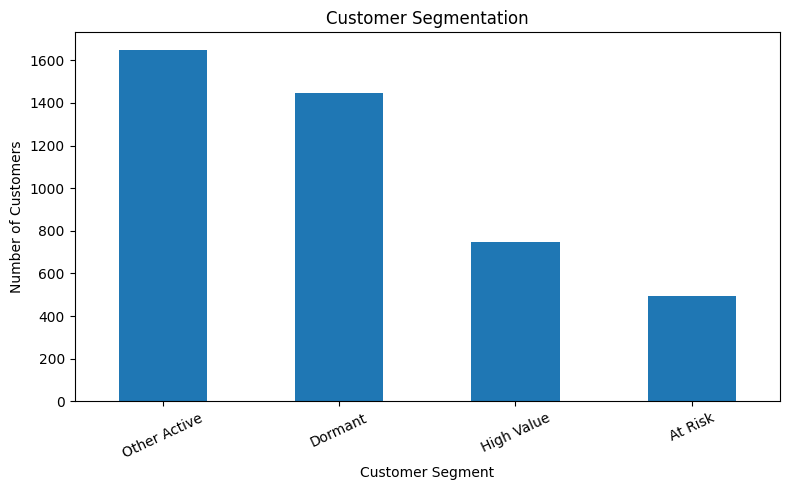

In [8]:

# Remove records without a customer ID for customer analysis
customer_df = df.dropna(subset=["CustomerID"]).copy()

# Aggregate customer metrics
customer_summary = (
    customer_df.groupby("CustomerID")
    .agg(
        TotalSpent=("Revenue", "sum"),
        TotalOrders=("InvoiceNo", "nunique"),
        LastPurchase=("InvoiceDate", "max")
    )
    .reset_index()
)

# Calculate days since the last purchase in the dataset
reference_date = customer_df["InvoiceDate"].max() + pd.Timedelta(days=1)

customer_summary["DaysSinceLastPurchase"] = (
    reference_date - customer_summary["LastPurchase"]
).dt.days

# Assign transparent, rule-based segments
spend_cutoff = customer_summary["TotalSpent"].quantile(0.75)
order_cutoff = customer_summary["TotalOrders"].quantile(0.75)

def assign_segment(row):
    if row["DaysSinceLastPurchase"] > 90:
        return "Dormant"
    elif row["DaysSinceLastPurchase"] > 60:
        return "At Risk"
    elif row["TotalSpent"] >= spend_cutoff and row["TotalOrders"] >= order_cutoff:
        return "High Value"
    else:
        return "Other Active"

customer_summary["Segment"] = customer_summary.apply(
    assign_segment, axis=1
)

print("Customer segment counts:")
display(
    customer_summary["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="CustomerCount")
)

print("\nTop 10 customers by total spending:")
display(
    customer_summary.sort_values("TotalSpent", ascending=False).head(10)
)

# Visualize segment sizes
customer_summary["Segment"].value_counts().plot(
    kind="bar", figsize=(8, 5)
)
plt.title("Customer Segmentation")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


In [9]:

import os
import zipfile

# Create a folder for project outputs
os.makedirs("retail_project_outputs", exist_ok=True)

# Save analysis tables
country_revenue.rename("Revenue").to_csv(
    "retail_project_outputs/revenue_by_country.csv"
)

product_revenue.rename("Revenue").to_csv(
    "retail_project_outputs/revenue_by_product.csv"
)

monthly_revenue.rename("Revenue").to_csv(
    "retail_project_outputs/monthly_revenue.csv"
)

customer_summary.to_csv(
    "retail_project_outputs/customer_segments.csv",
    index=False
)

# Save charts
plt.figure(figsize=(10, 5))
country_revenue.sort_values().plot(kind="barh")
plt.title("Top 10 Countries by Retail Revenue")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.savefig("retail_project_outputs/revenue_by_country.png", dpi=150)
plt.close()

plt.figure(figsize=(10, 5))
product_revenue.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Retail Revenue")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.savefig("retail_project_outputs/revenue_by_product.png", dpi=150)
plt.close()

plt.figure(figsize=(12, 5))
plt.plot(monthly_revenue.index.astype(str), monthly_revenue.values, marker="o")
plt.title("Monthly Retail Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.savefig("retail_project_outputs/monthly_revenue_trend.png", dpi=150)
plt.close()

customer_summary["Segment"].value_counts().plot(kind="bar", figsize=(8, 5))
plt.title("Customer Segmentation")
plt.xlabel("Segment")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("retail_project_outputs/customer_segmentation.png", dpi=150)
plt.close()

# Package everything into a ZIP file
with zipfile.ZipFile(
    "retail_project_outputs.zip", "w", zipfile.ZIP_DEFLATED
) as zip_file:
    for root, dirs, files in os.walk("retail_project_outputs"):
        for file in files:
            full_path = os.path.join(root, file)
            zip_file.write(full_path, arcname=full_path)

print("Export complete!")
print("Files saved in retail_project_outputs/")
print("ZIP file: retail_project_outputs.zip")


Export complete!
Files saved in retail_project_outputs/
ZIP file: retail_project_outputs.zip


In [10]:
from google.colab import files
files.download("retail_project_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>